In [2]:
import pandas as pd, numpy as np, glob, os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", "{:,.2f}".format)

path = [f for f in glob.glob("../data/raw/*") if f.lower().endswith((".csv", ".xlsx"))][0]
if path.lower().endswith(".csv"):
    df = pd.read_csv(path, encoding="latin-1")
else:
    df = pd.concat(pd.read_excel(path, sheet_name=None).values(), ignore_index=True)

df.columns = [c.strip().replace(" ", "_").lower() for c in df.columns]
df["invoicedate"] = pd.to_datetime(df["invoicedate"])
df["invoice"] = df["invoice"].astype(str)
df["stockcode"] = df["stockcode"].astype(str)
df["revenue"] = df["quantity"] * df["price"]
print("Raw rows:", len(df))


Raw rows: 1067371


In [3]:
log = []
def step(name, data):
    log.append({"step": name, "rows_after": len(data)})

step("Raw data", df)

# CR-01: remove exact duplicates
df = df.drop_duplicates()
step("CR-01 Remove duplicates", df)

# CR-03: remove price <= 0
df = df[df["price"] > 0]
step("CR-03 Remove price <= 0", df)

# CR-02: split cancellations (invoice starts with C) from sales
df["is_cancel"] = df["invoice"].str.startswith("C")
cancels = df[df["is_cancel"]].copy()
sales   = df[(~df["is_cancel"]) & (df["quantity"] > 0)].copy()
step("CR-02 Sales rows (cancellations separated)", sales)

# CR-04: product-only flag (5-digit stock codes) for product rankings
sales["is_product"] = sales["stockcode"].str.match(r"^\d{5}")

# CR-05: customers with ID only, for RFM later
sales["has_customer"] = sales["customer_id"].notna()

# Month column
sales["month"]   = sales["invoicedate"].dt.to_period("M").dt.to_timestamp()
cancels["month"] = cancels["invoicedate"].dt.to_period("M").dt.to_timestamp()

pd.DataFrame(log)


,step,rows_after
0,Raw data,1067371
1,CR-01 Remove duplicates,1033036
2,CR-03 Remove price <= 0,1027017
3,CR-02 Sales rows (cancellations separated),1007913


In [4]:
os.makedirs("../data/processed", exist_ok=True)
sales.to_csv("../data/processed/sales_clean.csv", index=False)
cancels.to_csv("../data/processed/cancellations_clean.csv", index=False)
print(len(sales), "sales rows,", len(cancels), "cancellation rows saved")


1007913 sales rows, 19104 cancellation rows saved


In [5]:
total_revenue   = sales["revenue"].sum()
total_orders    = sales["invoice"].nunique()
total_customers = sales["customer_id"].nunique()
total_units     = sales["quantity"].sum()
aov             = total_revenue / total_orders

cancel_value    = cancels["revenue"].abs().sum()
cancel_invoices = cancels["invoice"].nunique()
cancel_rate_val = cancel_value / total_revenue * 100
cancel_rate_ord = cancel_invoices / (total_orders + cancel_invoices) * 100

orders_per_cust = sales.dropna(subset=["customer_id"]).groupby("customer_id")["invoice"].nunique()
repeat_pct      = (orders_per_cust >= 2).mean() * 100

kpis = pd.DataFrame({
    "KPI": ["Total Revenue (£)", "Total Orders", "Total Customers", "Units Sold",
            "Average Order Value (£)", "Cancelled Value (£)", "Cancelled Invoices",
            "Cancellation Rate by Value (%)", "Cancellation Rate by Orders (%)",
            "Repeat Customer (%)"],
    "Value": [total_revenue, total_orders, total_customers, total_units,
              aov, cancel_value, cancel_invoices,
              cancel_rate_val, cancel_rate_ord, repeat_pct]
})
os.makedirs("../outputs/reports", exist_ok=True)
kpis.to_csv("../outputs/reports/kpi_summary.csv", index=False)
kpis


,KPI,Value
0,Total Revenue (£),"20,476,260.45"
1,Total Orders,"40,077.00"
2,Total Customers,"5,878.00"
3,Units Sold,"11,205,148.00"
4,Average Order Value (£),510.92
5,Cancelled Value (£),"1,462,797.75"
6,Cancelled Invoices,"8,292.00"
7,Cancellation Rate by Value (%),7.14
8,Cancellation Rate by Orders (%),17.14
9,Repeat Customer (%),72.39


In [6]:
monthly = sales.groupby("month").agg(revenue=("revenue", "sum"),
                                     orders=("invoice", "nunique"),
                                     customers=("customer_id", "nunique")).reset_index()
monthly["mom_growth_pct"] = monthly["revenue"].pct_change() * 100

canc_m = cancels.groupby("month")["revenue"].apply(lambda s: s.abs().sum()).rename("cancel_value")
monthly = monthly.merge(canc_m, on="month", how="left").fillna({"cancel_value": 0})
monthly["cancel_rate_pct"] = monthly["cancel_value"] / monthly["revenue"] * 100

monthly.to_csv("../outputs/reports/monthly_kpis.csv", index=False)
monthly


,month,revenue,orders,customers,mom_growth_pct,cancel_value,cancel_rate_pct
0,2009-12-01,"822,483.95",1682,955,NaN,"25,835.45",3.14
1,2010-01-01,"651,155.11",1105,720,-20.83,"28,675.61",4.40
2,2010-02-01,"551,504.73",1201,772,-15.30,"20,986.50",3.81
3,2010-03-01,"830,915.26",1681,1057,50.66,"67,668.02",8.14
4,2010-04-01,"678,875.25",1462,942,-18.30,"37,354.20",5.50
5,2010-05-01,"657,705.50",1500,966,-3.12,"44,434.78",6.76
6,2010-06-01,"749,537.31",1645,1041,13.96,"72,463.44",9.67
7,2010-07-01,"648,810.27",1529,928,-13.44,"31,444.79",4.85
8,2010-08-01,"695,251.91",1425,911,7.16,"40,477.52",5.82
9,2010-09-01,"921,696.99",1839,1145,32.57,"70,591.03",7.66


In [7]:
country = (sales.groupby("country")
                .agg(revenue=("revenue", "sum"), orders=("invoice", "nunique"),
                     customers=("customer_id", "nunique"))
                .sort_values("revenue", ascending=False).reset_index())
country["share_pct"] = country["revenue"] / country["revenue"].sum() * 100
country.to_csv("../outputs/reports/country_kpis.csv", index=False)

prod = (sales[sales["is_product"]]
        .groupby(["stockcode", "description"], dropna=False)
        .agg(revenue=("revenue", "sum"), units=("quantity", "sum")).reset_index())
top10    = prod.sort_values("revenue", ascending=False).head(10)
bottom10 = prod[prod["revenue"] > 0].sort_values("revenue").head(10)
prod.to_csv("../outputs/reports/product_kpis.csv", index=False)

print("Top countries:"); display(country.head(10))
print("Top 10 products:"); display(top10)
print("Bottom 10 products:"); display(bottom10)


Top countries:


,country,revenue,orders,customers,share_pct
0,United Kingdom,"17,410,196.12",36535,5350,85.03
1,EIRE,"658,767.31",626,5,3.22
2,Netherlands,"554,038.09",228,22,2.71
3,Germany,"425,019.71",789,107,2.08
4,France,"350,456.09",622,95,1.71
5,Australia,"169,283.46",95,15,0.83
6,Spain,"108,332.49",154,41,0.53
7,Switzerland,"100,685.59",93,22,0.49
8,Sweden,"91,869.82",105,19,0.45
9,Denmark,"68,580.69",43,12,0.33


Top 10 products:


,stockcode,description,revenue,units
1891,22423,REGENCY CAKESTAND 3 TIER,"330,590.32",26478
4999,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"257,546.20",94142
3355,23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995
3716,47566,PARTY BUNTING,"148,318.28",28200
4967,85099B,JUMBO BAG RED RETROSPOT,"145,961.83",77280
4640,84879,ASSORTED COLOUR BIRD ORNAMENT,"129,324.49",80082
1477,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"117,760.29",35084
2810,23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033
4058,79321,CHILLI LIGHTS,"80,540.88",15841
4227,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,"71,300.40",31409


Bottom 10 products:


,stockcode,description,revenue,units
3484,35930,PINK HEART CHRISTMAS DECORATION,0.38,1
4180,84205C,HAPPY BIRTHDAY GINGER CAT CARD,0.38,2
3044,23366,SET 12 COLOURING PENCILS DOILEY,0.65,1
4182,84206B,CAT W SUNGLASSES BLANK CARD,0.76,4
3809,51014c,"FEATHER PEN,COAL BLACK",0.83,1
282,20721,OWLS CHARLOTTE BAG,0.85,1
4183,84206B,CAT WITH SUNGLASSES BLANK CARD,0.95,5
3491,35950,FOLKART HEART CHRISTMAS DECORATIONS,1.25,1
3050,23370,SET 36 COLOURING PENCILS DOILEY,1.25,1
4595,84845A,HOLLYHOCK SQUARE HANDY TIN,1.25,1


In [9]:
print("Top 10 products share (%):", round(top10["revenue"].sum() / prod["revenue"].sum() * 100, 2))


Top 10 products share (%): 7.8


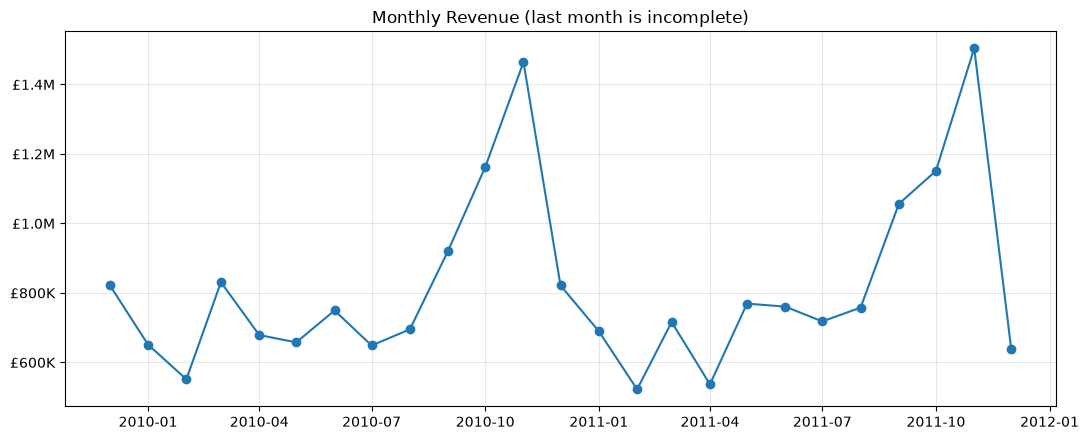

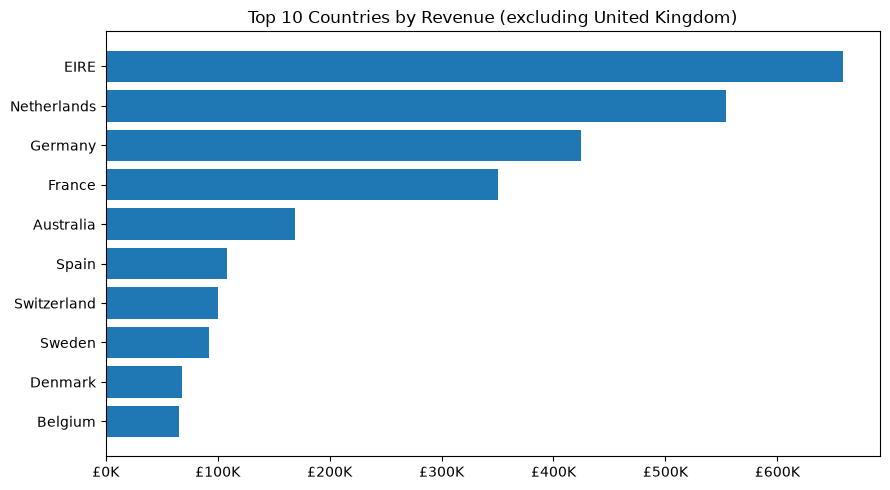

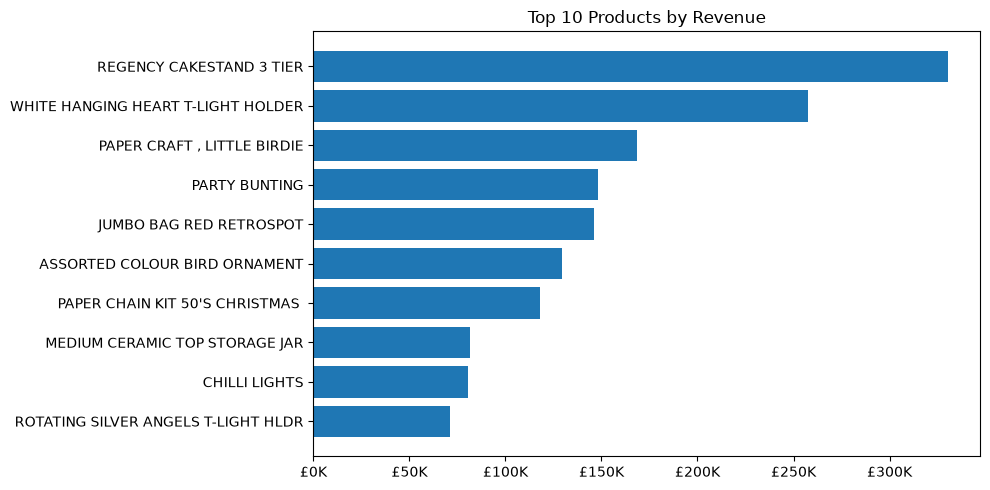

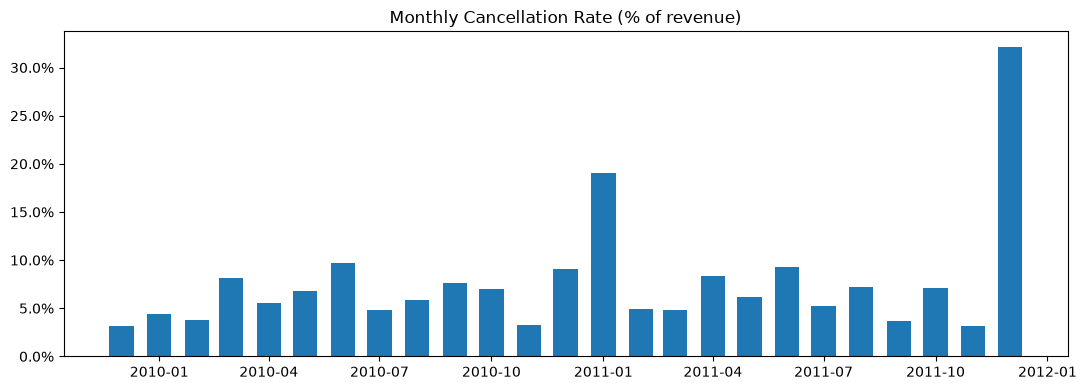

In [8]:
os.makedirs("../outputs/charts", exist_ok=True)
gbp = mtick.FuncFormatter(lambda x, _: f"£{x/1e6:.1f}M" if x >= 1e6 else f"£{x/1e3:.0f}K")

# 1. Monthly revenue trend
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly["month"], monthly["revenue"], marker="o")
ax.set_title("Monthly Revenue (last month is incomplete)"); ax.yaxis.set_major_formatter(gbp)
ax.grid(alpha=.3); plt.tight_layout()
plt.savefig("../outputs/charts/01_monthly_revenue.png", dpi=150); plt.show()

# 2. Top 10 countries excluding the UK
oth = country[country["country"] != "United Kingdom"].head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(oth["country"], oth["revenue"]); ax.xaxis.set_major_formatter(gbp)
ax.set_title("Top 10 Countries by Revenue (excluding United Kingdom)")
plt.tight_layout(); plt.savefig("../outputs/charts/02_top_countries.png", dpi=150); plt.show()

# 3. Top 10 products
t = top10.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(t["description"].fillna(t["stockcode"]).str[:35], t["revenue"]); ax.xaxis.set_major_formatter(gbp)
ax.set_title("Top 10 Products by Revenue"); plt.tight_layout()
plt.savefig("../outputs/charts/03_top_products.png", dpi=150); plt.show()

# 4. Monthly cancellation rate
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(monthly["month"], monthly["cancel_rate_pct"], width=20)
ax.set_title("Monthly Cancellation Rate (% of revenue)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); plt.tight_layout()
plt.savefig("../outputs/charts/04_cancellation_rate.png", dpi=150); plt.show()
